In [1]:
import kagglehub

# Download latest version
path = kagglehub.dataset_download("paultimothymooney/chest-xray-pneumonia")

print("Path to dataset files:", path)

Path to dataset files: /kaggle/input/chest-xray-pneumonia


In [2]:
import math, random, os, numpy as np, matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers


SEED = 42
tf.keras.utils.set_random_seed(SEED)

IMG_SIZE = (224, 224)
BATCH_SIZE = 32
VAL_SPLIT = 0.2
EPOCHS_A = 4
EPOCHS_B = 4


2025-10-29 11:02:56.423172: E external/local_xla/xla/stream_executor/cuda/cuda_fft.cc:477] Unable to register cuFFT factory: Attempting to register factory for plugin cuFFT when one has already been registered
E0000 00:00:1761735776.861235      19 cuda_dnn.cc:8310] Unable to register cuDNN factory: Attempting to register factory for plugin cuDNN when one has already been registered
E0000 00:00:1761735776.982881      19 cuda_blas.cc:1418] Unable to register cuBLAS factory: Attempting to register factory for plugin cuBLAS when one has already been registered


In [3]:
import os
import shutil

SOURCE_DIR = "/kaggle/input/chest-xray-pneumonia/chest_xray/chest_xray"
TARGET_DIR = "/kaggle/working/chest_xray_cleaned"

if not os.path.exists(TARGET_DIR):
    shutil.copytree(SOURCE_DIR, TARGET_DIR)


In [4]:
from PIL import Image

def clean_dataset(root_dir):
    invalid_files = 0
    for root, _, files in os.walk(root_dir):
        for f in files:
            path = os.path.join(root, f)
            if f.startswith('.') or f.startswith('._') or f.endswith('.DS_Store'):
                os.remove(path)
                invalid_files += 1
                continue
            try:
                with Image.open(path) as img:
                    img.verify()
            except:
                os.remove(path)
                invalid_files += 1
    print(f"🧹 {invalid_files} fichiers invalides supprimés.")
    
clean_dataset(TARGET_DIR)


🧹 8 fichiers invalides supprimés.


In [5]:
import os
import shutil

# Chemins
BASE_DIR = "/kaggle/working/chest_xray_cleaned"  # dossier qui contient train, val, test
TARGET_DIR = "/kaggle/working/chest_xray_merged"

os.makedirs(TARGET_DIR, exist_ok=True)

# Classes (NORMAL, PNEUMONIA)
classes = ["NORMAL", "PNEUMONIA"]

for cls in classes:
    target_class_dir = os.path.join(TARGET_DIR, cls)
    os.makedirs(target_class_dir, exist_ok=True)
    
    # Parcourir train, val, test
    for split in ["train", "val", "test"]:
        split_class_dir = os.path.join(BASE_DIR, split, cls)
        if not os.path.exists(split_class_dir):
            continue
        for f in os.listdir(split_class_dir):
            if f.startswith('.') or f.startswith('._') or f.endswith('.DS_Store'):
                continue
            src_path = os.path.join(split_class_dir, f)
            dst_path = os.path.join(target_class_dir, f)
            
            # Si même nom de fichier existe, renommer pour éviter écrasement
            if os.path.exists(dst_path):
                base, ext = os.path.splitext(f)
                dst_path = os.path.join(target_class_dir, f"{base}_copy{ext}")
            
            shutil.copy(src_path, dst_path)

print(f"✅ Toutes les images de train, val et test ont été fusionnées dans {TARGET_DIR}")


✅ Toutes les images de train, val et test ont été fusionnées dans /kaggle/working/chest_xray_merged


In [6]:
import os
import random
import shutil

# Dossier propre
SOURCE_DIR = "/kaggle/working/chest_xray_merged"
TARGET_DIR = "/kaggle/working/chest_xray_final"

TRAIN_RATIO = 0.8  # 80% train, 20% validation

os.makedirs(TARGET_DIR, exist_ok=True)

classes = [d for d in os.listdir(SOURCE_DIR) if os.path.isdir(os.path.join(SOURCE_DIR, d))]

for cls in classes:
    cls_dir = os.path.join(SOURCE_DIR, cls)
    images = [f for f in os.listdir(cls_dir) if os.path.isfile(os.path.join(cls_dir, f))]
    random.shuffle(images)  # Mélanger les images
    
    # Calcul des indices de split
    split_idx = int(len(images) * TRAIN_RATIO)
    train_images = images[:split_idx]
    val_images = images[split_idx:]
    
    # Créer dossiers train/val pour cette classe
    train_dir = os.path.join(TARGET_DIR, "train", cls)
    val_dir = os.path.join(TARGET_DIR, "val", cls)
    os.makedirs(train_dir, exist_ok=True)
    os.makedirs(val_dir, exist_ok=True)
    
    # Copier les fichiers
    for f in train_images:
        shutil.copy(os.path.join(cls_dir, f), os.path.join(train_dir, f))
    for f in val_images:
        shutil.copy(os.path.join(cls_dir, f), os.path.join(val_dir, f))

print("✅ Split 80/20 créé avec succès dans :", TARGET_DIR)


✅ Split 80/20 créé avec succès dans : /kaggle/working/chest_xray_final


In [7]:
import os

BASE_DIR = "/kaggle/working/chest_xray_final/train"

for cls in os.listdir(BASE_DIR):
    cls_dir = os.path.join(BASE_DIR, cls)
    if os.path.isdir(cls_dir):
        files = [f for f in os.listdir(cls_dir) if os.path.isfile(os.path.join(cls_dir, f))]
        print(f"📂 {cls}: {len(files)} images")


📂 PNEUMONIA: 3418 images
📂 NORMAL: 1266 images


In [8]:
import tensorflow as tf

IMG_SIZE = (224, 224)
BATCH_SIZE = 32

train_ds = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(TARGET_DIR, "/kaggle/working/chest_xray_final/train"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=True
)

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    os.path.join(TARGET_DIR, "/kaggle/working/chest_xray_final/val"),
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

Found 4684 files belonging to 2 classes.


I0000 00:00:1761735866.898035      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 13942 MB memory:  -> device: 0, name: Tesla T4, pci bus id: 0000:00:04.0, compute capability: 7.5
I0000 00:00:1761735866.898804      19 gpu_device.cc:2022] Created device /job:localhost/replica:0/task:0/device:GPU:1 with 13942 MB memory:  -> device: 1, name: Tesla T4, pci bus id: 0000:00:05.0, compute capability: 7.5


Found 1172 files belonging to 2 classes.


In [9]:
from tensorflow.keras.applications import VGG16
base_model_A = VGG16(include_top=False, weights="imagenet", input_shape=IMG_SIZE+(3,))

for layer in base_model_A.layers:
    layer.trainable = False

inputs_A = keras.Input(shape=IMG_SIZE+(3,), name="inputs_A")
x_A = base_model_A(inputs_A, training=False)

x_A = layers.GlobalAveragePooling2D()(x_A)
x_A = layers.Dense(256, activation="relu")(x_A)
x_A = layers.Dropout(0.3)(x_A)
x_A = layers.Dense(128, activation="relu")(x_A)
x_A = layers.Dropout(0.2)(x_A)

# Sortie binaire -> une seule unité avec sigmoid
outputs_A = layers.Dense(1, activation="sigmoid")(x_A)

model_A = keras.Model(inputs_A, outputs_A, name="VGG16_FROZEN_BINARY")
model_A.summary()

58889256/58889256 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step


Model: "VGG16_FROZEN_BINARY"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inputs_A (InputLayer)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ vgg16 (Functional)              │ (None, 7, 7, 512)      │    14,714,688 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d        │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_1 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_2 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 14,879,041 (56.76 MB)

 Trainable params: 164,353 (642.00 KB)

 Non-trainable params: 14,714,688 (56.13 MB)

In [10]:
# Compilation (loss binaire)
model_A.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-3),
    loss="binary_crossentropy",   # ✅ pour deux classes
    metrics=["accuracy"]
)

# Entraînement
history_A = model_A.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_A,
    verbose=1
)

# Évaluation
val_loss_A, val_acc_A = model_A.evaluate(val_ds, verbose=0)
print(f"✅ Scénario A — Validation Accuracy: {val_acc_A:.4f}, Validation Loss: {val_loss_A:.4f}")


Epoch 1/4


I0000 00:00:1761735882.137367      68 service.cc:148] XLA service 0x78196400fd20 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1761735882.140668      68 service.cc:156]   StreamExecutor device (0): Tesla T4, Compute Capability 7.5
I0000 00:00:1761735882.140749      68 service.cc:156]   StreamExecutor device (1): Tesla T4, Compute Capability 7.5
I0000 00:00:1761735882.875165      68 cuda_dnn.cc:529] Loaded cuDNN version 90300


  1/147 ━━━━━━━━━━━━━━━━━━━━ 38:50 16s/step - accuracy: 0.4062 - loss: 2.0945

I0000 00:00:1761735895.111198      68 device_compiler.h:188] Compiled cluster using XLA!  This line is logged at most once for the lifetime of the process.


147/147 ━━━━━━━━━━━━━━━━━━━━ 59s 294ms/step - accuracy: 0.8322 - loss: 0.5359 - val_accuracy: 0.9078 - val_loss: 0.2369
Epoch 2/4
147/147 ━━━━━━━━━━━━━━━━━━━━ 30s 206ms/step - accuracy: 0.9292 - loss: 0.1789 - val_accuracy: 0.9172 - val_loss: 0.2165
Epoch 3/4
147/147 ━━━━━━━━━━━━━━━━━━━━ 33s 223ms/step - accuracy: 0.9456 - loss: 0.1373 - val_accuracy: 0.9334 - val_loss: 0.1831
Epoch 4/4
147/147 ━━━━━━━━━━━━━━━━━━━━ 33s 225ms/step - accuracy: 0.9517 - loss: 0.1301 - val_accuracy: 0.9556 - val_loss: 0.1425
✅ Scénario A — Validation Accuracy: 0.9556, Validation Loss: 0.1425


1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 1s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 218ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 250ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 226ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 229ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 203ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 210ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 222ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 213ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 207ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 202ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 199ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 206ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 204ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 211ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 221ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 197ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 

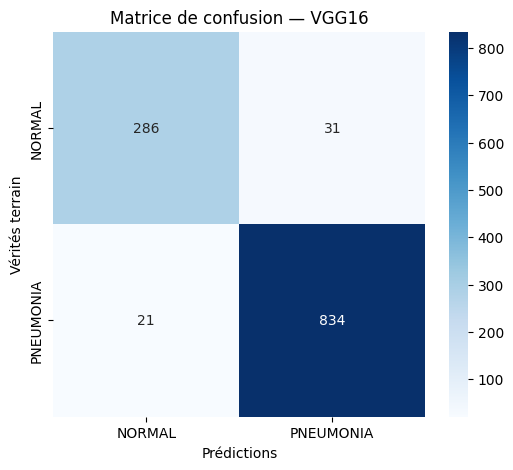


📊 Rapport de classification :
              precision    recall  f1-score   support

      NORMAL       0.93      0.90      0.92       317
   PNEUMONIA       0.96      0.98      0.97       855

    accuracy                           0.96      1172
   macro avg       0.95      0.94      0.94      1172
weighted avg       0.96      0.96      0.96      1172



In [11]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report

# 🔹 Charger ton modèle (si tu l’as sauvegardé)
#model_A = keras.models.load_model("/kaggle/input/vgg16-frozen-h5/tensorflow2/default/1")

# 🔹 Prédictions sur le jeu de validation
y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model_A.predict(images)
    preds = (preds > 0.5).astype("int32")  # car sigmoid -> binaire
    y_true.extend(labels.numpy())
    y_pred.extend(preds.reshape(-1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 🔹 Matrice de confusion
cm = confusion_matrix(y_true, y_pred)
class_names = val_ds.class_names  # ex: ['NORMAL', 'PNEUMONIA']

plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", 
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédictions")
plt.ylabel("Vérités terrain")
plt.title("Matrice de confusion — VGG16")
plt.show()

# 🔹 Rapport de classification (Precision, Recall, F1-score)
print("\n📊 Rapport de classification :")
print(classification_report(y_true, y_pred, target_names=class_names))


In [12]:
# Chemin où enregistrer le modèle
model_path = "/kaggle/working/vgg16_frozen.h5"

# Sauvegarde
model_A.save(model_path)
print(f"✅ Modèle sauvegardé ici : {model_path}")

✅ Modèle sauvegardé ici : /kaggle/working/vgg16_frozen.h5


In [13]:
from tensorflow.keras.applications import DenseNet121

# --- Définir la taille des images ---
# Exemple : IMG_SIZE = (224, 224)
# num_classes = 1 pour binaire, >1 pour multi-classes

# --- Base model DenseNet121 ---
base_model_D = DenseNet121(include_top=False, weights="imagenet", input_shape=IMG_SIZE+(3,))

# --- Dégel de toutes les couches pour fine-tuning complet ---
for layer in base_model_D.layers:
    layer.trainable = True

trainable_layers = sum(1 for l in base_model_D.layers if l.trainable)
print(f"Couches entraînables (scénario D): {trainable_layers} / {len(base_model_D.layers)}")

# --- Entrée du modèle ---
inputs_D = keras.Input(shape=IMG_SIZE+(3,), name="inputs_D")

# --- Passage par le backbone DenseNet121 ---
x_D = base_model_D(inputs_D, training=True)

# --- Couches additionnelles personnalisées ---
x_D = layers.Conv2D(512, 3, padding="same")(x_D)
x_D = layers.BatchNormalization()(x_D)
x_D = layers.ReLU()(x_D)

x_D = layers.GlobalAveragePooling2D()(x_D)
x_D = layers.Dense(256, activation="relu")(x_D)
x_D = layers.Dropout(0.3)(x_D)
x_D = layers.Dense(128, activation="relu")(x_D)
x_D = layers.Dropout(0.2)(x_D)

# --- Sortie ---
# Classification binaire
outputs_D = layers.Dense(1, activation="sigmoid")(x_D)

# Classification multi-classes (si num_classes > 2)
# outputs_D = layers.Dense(num_classes, activation="softmax")(x_D)

# --- Création du modèle final ---
model_D = keras.Model(inputs_D, outputs_D, name="DenseNet121_FINETUNE_FULL")
model_D.summary()


29084464/29084464 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Couches entraînables (scénario D): 427 / 427


Model: "DenseNet121_FINETUNE_FULL"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inputs_D (InputLayer)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ densenet121 (Functional)        │ (None, 7, 7, 1024)     │     7,037,504 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 7, 7, 512)      │     4,719,104 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 7, 7, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu (ReLU)                    │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_1      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_3 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_2 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_4 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_3 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_5 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 11,923,009 (45.48 MB)

 Trainable params: 11,838,337 (45.16 MB)

 Non-trainable params: 84,672 (330.75 KB)

In [14]:
# Pour classification binaire
model_D.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-5),  # learning rate faible pour fine-tuning complet
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

# Entraînement
EPOCHS_D = 10
history_D = model_D.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_D,
    verbose=1
)

Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 353s 1s/step - accuracy: 0.6975 - loss: 0.5462 - val_accuracy: 0.9266 - val_loss: 0.2194
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 52s 351ms/step - accuracy: 0.9570 - loss: 0.1602 - val_accuracy: 0.9548 - val_loss: 0.1218
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 50s 342ms/step - accuracy: 0.9760 - loss: 0.0939 - val_accuracy: 0.9642 - val_loss: 0.1098
Epoch 4/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 51s 345ms/step - accuracy: 0.9853 - loss: 0.0600 - val_accuracy: 0.9590 - val_loss: 0.1287
Epoch 5/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 50s 341ms/step - accuracy: 0.9931 - loss: 0.0368 - val_accuracy: 0.9582 - val_loss: 0.1323
Epoch 6/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 51s 343ms/step - accuracy: 0.9964 - loss: 0.0210 - val_accuracy: 0.9659 - val_loss: 0.1207
Epoch 7/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 50s 341ms/step - accuracy: 0.9958 - loss: 0.0181 - val_accuracy: 0.9087 - val_loss: 0.3375
Epoch 8/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 51s 345ms/step - accuracy: 0.9981 - loss: 0.0

In [15]:
model_D.save("/kaggle/working/densenet121_finetune_full.h5")
print("💾 Modèle sauvegardé : /kaggle/working/densenet121_finetune_full.h5")

💾 Modèle sauvegardé : /kaggle/working/densenet121_finetune_full.h5


1/1 ━━━━━━━━━━━━━━━━━━━━ 11s 11s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 147ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 142ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 180ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 145ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 170ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 127ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 123ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 116ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 121ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 117ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 126ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 119ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 113ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 105ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 111ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 107ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 104ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0

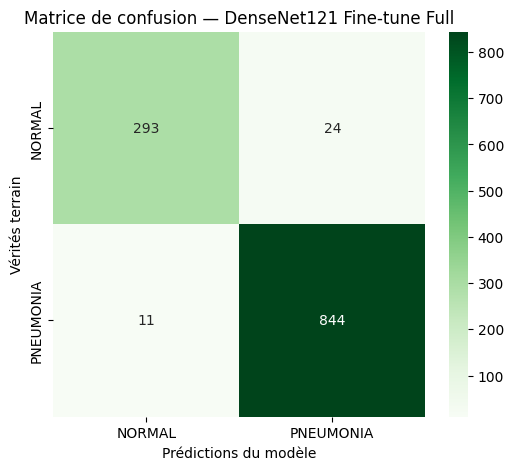


📊 Rapport de classification — DenseNet121 :
              precision    recall  f1-score   support

      NORMAL       0.96      0.92      0.94       317
   PNEUMONIA       0.97      0.99      0.98       855

    accuracy                           0.97      1172
   macro avg       0.97      0.96      0.96      1172
weighted avg       0.97      0.97      0.97      1172



In [16]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow import keras

# 🔹 Charger le modèle DenseNet121 (si sauvegardé)
model_D = keras.models.load_model("densenet121_finetune_full.h5")

# 🔹 Prédictions sur le jeu de validation
y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model_D.predict(images)
    preds = (preds > 0.5).astype("int32")  # Sigmoid → binaire
    y_true.extend(labels.numpy())
    y_pred.extend(preds.reshape(-1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 🔹 Créer la matrice de confusion
cm = confusion_matrix(y_true, y_pred)
class_names = val_ds.class_names  # Exemple: ['NORMAL', 'PNEUMONIA']

# 🔹 Affichage visuel
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Greens",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédictions du modèle")
plt.ylabel("Vérités terrain")
plt.title("Matrice de confusion — DenseNet121 Fine-tune Full")
plt.show()

# 🔹 Rapport de classification détaillé
print("\n📊 Rapport de classification — DenseNet121 :")
print(classification_report(y_true, y_pred, target_names=class_names))


In [17]:
from tensorflow import keras
from tensorflow.keras import layers
from tensorflow.keras.applications import EfficientNetB0
from tensorflow.keras.applications.efficientnet import preprocess_input

# --- Définir taille des images et nombre de classes ---
# Exemple : IMG_SIZE = (224, 224)
# num_classes = 1 pour binaire

# --- Base model EfficientNetB0 ---
base_model_E = EfficientNetB0(include_top=False, weights="imagenet", input_shape=IMG_SIZE+(3,))

# --- Freezing initial layers, unfreeze last block for fine-tuning ---
unfreeze = False
for layer in base_model_E.layers:
    if "block7" in layer.name:  # fine-tuning du dernier bloc
        unfreeze = True
    layer.trainable = unfreeze

trainable_layers = sum(1 for l in base_model_E.layers if l.trainable)
print(f"Couches entraînables (scénario E): {trainable_layers} / {len(base_model_E.layers)}")

# --- Entrée du modèle ---
inputs_E = keras.Input(shape=IMG_SIZE+(3,), name="inputs_E")

# --- Preprocessing ---
x_E = preprocess_input(inputs_E)

# --- Passage par le backbone EfficientNetB0 ---
x_E = base_model_E(x_E, training=True)

# --- Couches additionnelles personnalisées ---
x_E = layers.Conv2D(512, 3, padding="same")(x_E)
x_E = layers.BatchNormalization()(x_E)
x_E = layers.ReLU()(x_E)

x_E = layers.GlobalAveragePooling2D()(x_E)
x_E = layers.Dense(256, activation="relu")(x_E)
x_E = layers.Dropout(0.3)(x_E)
x_E = layers.Dense(128, activation="relu")(x_E)
x_E = layers.Dropout(0.2)(x_E)

# --- Sortie binaire ---
outputs_E = layers.Dense(1, activation="sigmoid")(x_E)

# --- Création du modèle final ---
model_E = keras.Model(inputs_E, outputs_E, name="EfficientNetB0_FINETUNE_BLOCK7_PLUS")
model_E.summary()


16705208/16705208 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Couches entraînables (scénario E): 16 / 238


Model: "EfficientNetB0_FINETUNE_BLOCK7_PLUS"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ inputs_E (InputLayer)           │ (None, 224, 224, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ efficientnetb0 (Functional)     │ (None, 7, 7, 1280)     │     4,049,571 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 7, 7, 512)      │     5,898,752 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 512)      │         2,048 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ re_lu_1 (ReLU)                  │ (None, 7, 7, 512)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ global_average_pooling2d_2      │ (None, 512)            │             0 │
│ (GlobalAveragePooling2D)        │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_6 (Dense)                 │ (None, 256)            │       131,328 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_4 (Dropout)             │ (None, 256)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_7 (Dense)                 │ (None, 128)            │        32,896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout_5 (Dropout)             │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_8 (Dense)                 │ (None, 1)              │           129 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 10,114,724 (38.58 MB)

 Trainable params: 7,193,521 (27.44 MB)

 Non-trainable params: 2,921,203 (11.14 MB)

In [18]:
model_E.compile(
    optimizer=keras.optimizers.Adam(learning_rate=1e-4),  # learning rate faible pour fine-tuning
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

EPOCHS_E = 10
history_E = model_E.fit(
    train_ds,
    validation_data=val_ds,
    epochs=EPOCHS_E,
    verbose=1
)

Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 80s 297ms/step - accuracy: 0.8977 - loss: 0.2707 - val_accuracy: 0.9138 - val_loss: 0.2208
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 18s 121ms/step - accuracy: 0.9580 - loss: 0.1137 - val_accuracy: 0.9522 - val_loss: 0.1325
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 18s 124ms/step - accuracy: 0.9727 - loss: 0.0839 - val_accuracy: 0.9633 - val_loss: 0.1172
Epoch 4/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 16s 109ms/step - accuracy: 0.9714 - loss: 0.0712 - val_accuracy: 0.9642 - val_loss: 0.1114
Epoch 5/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - accuracy: 0.9833 - loss: 0.0487 - val_accuracy: 0.9599 - val_loss: 0.1340
Epoch 6/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - accuracy: 0.9863 - loss: 0.0399 - val_accuracy: 0.9642 - val_loss: 0.1210
Epoch 7/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 18s 125ms/step - accuracy: 0.9852 - loss: 0.0395 - val_accuracy: 0.9650 - val_loss: 0.1267
Epoch 8/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 16s 110ms/step - accuracy: 0.9877 - loss: 0

In [19]:
model_E.save("/kaggle/working/efficientnetb0_finetune_block7.h5")
print("💾 Modèle sauvegardé : /kaggle/working/efficientnetb0_finetune_block7.h5")

💾 Modèle sauvegardé : /kaggle/working/efficientnetb0_finetune_block7.h5


1/1 ━━━━━━━━━━━━━━━━━━━━ 7s 7s/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 115ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 114ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 124ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 159ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 128ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 130ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 102ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 96ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 95ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 90ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 99ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 97ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 87ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 94ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 92ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 88ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 89ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 84ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 82ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 81ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 83ms/step
1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 86ms/step
1/1 ━━━

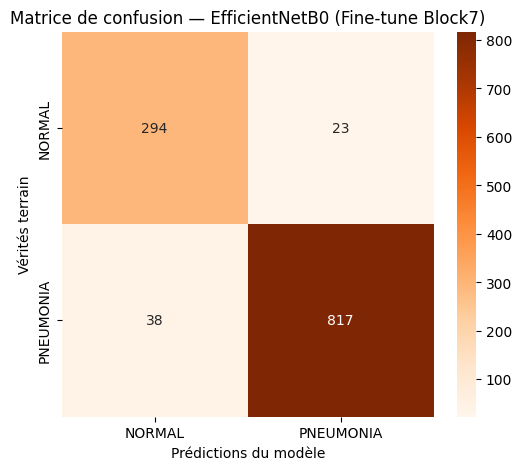


📊 Rapport de classification — EfficientNetB0 :
              precision    recall  f1-score   support

      NORMAL       0.89      0.93      0.91       317
   PNEUMONIA       0.97      0.96      0.96       855

    accuracy                           0.95      1172
   macro avg       0.93      0.94      0.94      1172
weighted avg       0.95      0.95      0.95      1172



In [20]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix, classification_report
from tensorflow import keras

# 🔹 Charger ton modèle EfficientNetB0
model_E = keras.models.load_model("efficientnetb0_finetune_block7.h5")

# 🔹 Génération des prédictions sur le jeu de validation
y_true = []
y_pred = []

for images, labels in val_ds:
    preds = model_E.predict(images)
    preds = (preds > 0.5).astype("int32")  # activation sigmoid → binaire
    y_true.extend(labels.numpy())
    y_pred.extend(preds.reshape(-1))

y_true = np.array(y_true)
y_pred = np.array(y_pred)

# 🔹 Création de la matrice de confusion
cm = confusion_matrix(y_true, y_pred)
class_names = val_ds.class_names  # ex. ['NORMAL', 'PNEUMONIA']

# 🔹 Visualisation avec seaborn
plt.figure(figsize=(6,5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Oranges",
            xticklabels=class_names, yticklabels=class_names)
plt.xlabel("Prédictions du modèle")
plt.ylabel("Vérités terrain")
plt.title("Matrice de confusion — EfficientNetB0 (Fine-tune Block7)")
plt.show()

# 🔹 Rapport de classification détaillé
print("\n📊 Rapport de classification — EfficientNetB0 :")
print(classification_report(y_true, y_pred, target_names=class_names))


In [21]:
from tensorflow.keras.applications import DenseNet121, EfficientNetB0
from tensorflow.keras import layers, Model, Input
from tensorflow.keras.models import load_model
import tensorflow as tf

IMG_SIZE = (224, 224)  # adapte si différent
num_classes = 1  # binaire

# === 1️⃣ Charger les deux modèles préentraînés ===
base_densenet = DenseNet121(
    include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,)
)
base_efficientnet = EfficientNetB0(
    include_top=False, weights="imagenet", input_shape=IMG_SIZE + (3,)
)

# === 2️⃣ Geler les poids (on peut les dégeler plus tard pour fine-tuning complet) ===
for layer in base_densenet.layers:
    layer.trainable = False

for layer in base_efficientnet.layers:
    layer.trainable = False

# === 3️⃣ Entrées partagées ===
inputs = Input(shape=IMG_SIZE + (3,), name="input_image")

# === 4️⃣ Extraire les features des deux modèles ===
x1 = base_densenet(inputs, training=False)
x1 = layers.GlobalAveragePooling2D()(x1)

x2 = base_efficientnet(inputs, training=False)
x2 = layers.GlobalAveragePooling2D()(x2)

# === 5️⃣ Fusion (concaténation des features) ===
x = layers.Concatenate()([x1, x2])
x = layers.Dense(256, activation="relu")(x)
x = layers.Dropout(0.3)(x)
x = layers.Dense(128, activation="relu")(x)
x = layers.Dropout(0.2)(x)

# === 6️⃣ Sortie binaire ===
outputs = layers.Dense(1, activation="sigmoid")(x)

# === 7️⃣ Définir le modèle final ===
fusion_model = Model(inputs, outputs, name="Fusion_DenseNet_EfficientNet")

fusion_model.compile(
    optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
    loss="binary_crossentropy",
    metrics=["accuracy"]
)

fusion_model.summary()


Model: "Fusion_DenseNet_EfficientNet"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_image         │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ densenet121         │ (None, 7, 7,      │  7,037,504 │ input_image[0][0] │
│ (Functional)        │ 1024)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ efficientnetb0      │ (None, 7, 7,      │  4,049,571 │ input_image[0][0] │
│ (Functional)        │ 1280)             │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1024)      │          0 │ densenet121[0][0] │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ global_average_poo… │ (None, 1280)      │          0 │ efficientnetb0[0… │
│ (GlobalAveragePool… │                   │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ concatenate         │ (None, 2304)      │          0 │ global_average_p… │
│ (Concatenate)       │                   │            │ global_average_p… │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_9 (Dense)     │ (None, 256)       │    590,080 │ concatenate[0][0] │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_6 (Dropout) │ (None, 256)       │          0 │ dense_9[0][0]     │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_10 (Dense)    │ (None, 128)       │     32,896 │ dropout_6[0][0]   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dropout_7 (Dropout) │ (None, 128)       │          0 │ dense_10[0][0]    │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ dense_11 (Dense)    │ (None, 1)         │        129 │ dropout_7[0][0]   │
└─────────────────────┴───────────────────┴────────────┴───────────────────┘

 Total params: 11,710,180 (44.67 MB)

 Trainable params: 623,105 (2.38 MB)

 Non-trainable params: 11,087,075 (42.29 MB)

In [22]:
history_fusion = fusion_model.fit(
    train_ds,
    validation_data=val_ds,
    epochs=10,
    verbose=1
)

Epoch 1/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 122s 461ms/step - accuracy: 0.7260 - loss: 0.6858 - val_accuracy: 0.9121 - val_loss: 0.2277
Epoch 2/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 22s 146ms/step - accuracy: 0.8946 - loss: 0.2466 - val_accuracy: 0.9352 - val_loss: 0.1885
Epoch 3/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 21s 145ms/step - accuracy: 0.9266 - loss: 0.1902 - val_accuracy: 0.9411 - val_loss: 0.1631
Epoch 4/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 21s 141ms/step - accuracy: 0.9359 - loss: 0.1651 - val_accuracy: 0.9394 - val_loss: 0.1530
Epoch 5/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 21s 142ms/step - accuracy: 0.9492 - loss: 0.1435 - val_accuracy: 0.9437 - val_loss: 0.1470
Epoch 6/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 21s 142ms/step - accuracy: 0.9552 - loss: 0.1260 - val_accuracy: 0.9428 - val_loss: 0.1447
Epoch 7/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 21s 143ms/step - accuracy: 0.9522 - loss: 0.1318 - val_accuracy: 0.9411 - val_loss: 0.1439
Epoch 8/10
147/147 ━━━━━━━━━━━━━━━━━━━━ 21s 143ms/step - accuracy: 0.9580 - loss: 

In [23]:
fusion_model.save("fusion_densenet_efficientnet.h5")
print("✅ Modèle combiné sauvegardé sous fusion_densenet_efficientnet.h5")


✅ Modèle combiné sauvegardé sous fusion_densenet_efficientnet.h5


Found 1172 files belonging to 2 classes.
37/37 ━━━━━━━━━━━━━━━━━━━━ 42s 680ms/step


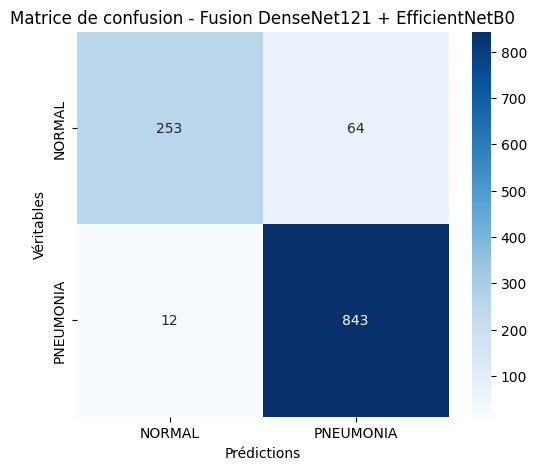


📊 Rapport de classification :

              precision    recall  f1-score   support

      NORMAL       0.95      0.80      0.87       317
   PNEUMONIA       0.93      0.99      0.96       855

    accuracy                           0.94      1172
   macro avg       0.94      0.89      0.91      1172
weighted avg       0.94      0.94      0.93      1172



In [24]:
import tensorflow as tf
from tensorflow import keras
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import confusion_matrix, classification_report, ConfusionMatrixDisplay
import seaborn as sns
import os

# === 1. Charger le modèle fusionné ===
model = keras.models.load_model("/kaggle/working/fusion_densenet_efficientnet.h5")

# === 2. Charger le dataset de validation ===
IMG_SIZE = (224, 224)
BATCH_SIZE = 32
VAL_DIR = "/kaggle/working/chest_xray_final/val"  # adapte le chemin si besoin

val_ds = tf.keras.preprocessing.image_dataset_from_directory(
    VAL_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    label_mode="int",
    shuffle=False
)

# === 3. Extraire les vraies étiquettes ===
y_true = np.concatenate([y for x, y in val_ds], axis=0)

# === 4. Prédictions ===
y_pred_probs = model.predict(val_ds)
# Si binaire, appliquer un seuil 0.5
if y_pred_probs.shape[1] == 1:
    y_pred = (y_pred_probs > 0.5).astype("int32").flatten()
else:
    y_pred = np.argmax(y_pred_probs, axis=1)

# === 5. Matrice de confusion ===
cm = confusion_matrix(y_true, y_pred)
labels = val_ds.class_names

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt="d", cmap="Blues", xticklabels=labels, yticklabels=labels)
plt.xlabel("Prédictions")
plt.ylabel("Véritables")
plt.title("Matrice de confusion - Fusion DenseNet121 + EfficientNetB0")
plt.show()

# === 6. Rapport de classification ===
print("\n📊 Rapport de classification :\n")
print(classification_report(y_true, y_pred, target_names=labels))
